<a href="https://colab.research.google.com/github/andyotani/andyotani-PCVK_Ganjil_26-27/blob/main/Jobsheet06/JS06_pcvk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PRAKTIKUM FILTER

In [135]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [136]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import math
from google.colab.patches import cv2_imshow
from PIL import Image as im

In [137]:
def convolution2d(image, kernel, stride=1, padding=0):

    # menambahkan padding
    if padding > 0:
        image = np.pad(
            image,
            ((padding, padding), (padding, padding)),
            mode='constant'
        )

    image_height, image_width = image.shape
    kernel_height, kernel_width = kernel.shape

    output_height = int(
        (image_height - kernel_height) / stride
    ) + 1

    output_width = int(
        (image_width - kernel_width) / stride
    ) + 1

    output = np.zeros(
        (output_height, output_width)
    )


    for y in range(0, output_height):

        for x in range(0, output_width):

            region = image[
                y*stride:y*stride+kernel_height,
                x*stride:x*stride+kernel_width
            ]

            output[y,x] = np.sum(
                region * kernel
            )

    return output

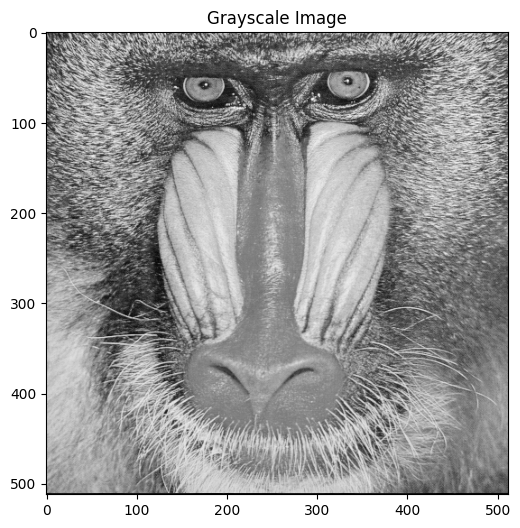

In [138]:
img = cv.imread('/content/drive/MyDrive/PCVK/Images/mandrill.tiff')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

plt.figure(figsize=(6,6))
plt.imshow(img_gray,cmap='gray')
plt.title("Grayscale Image")
plt.axis("on")
plt.show()

In [139]:
kernel_sharpen = np.array([
    [0,-1,0],
    [-1,5,-1],
    [0,-1,0]
])

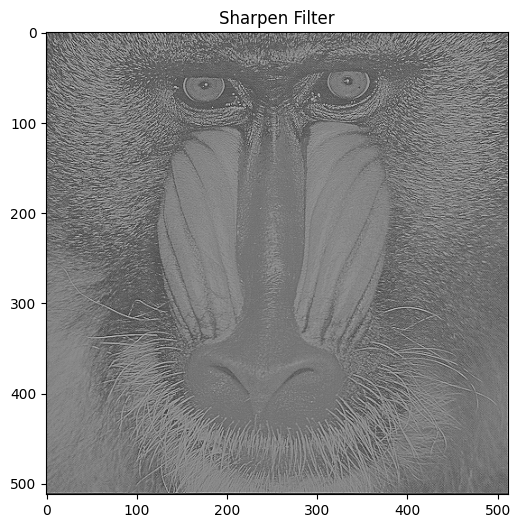

In [140]:
hasil_sharpen = convolution2d(
    img_gray,
    kernel_sharpen,
    stride=1,
    padding=1
)


plt.figure(figsize=(6,6))
plt.imshow(
    hasil_sharpen,
    cmap='gray'
)

plt.title(
    "Sharpen Filter"
)

plt.axis("on")
plt.show()

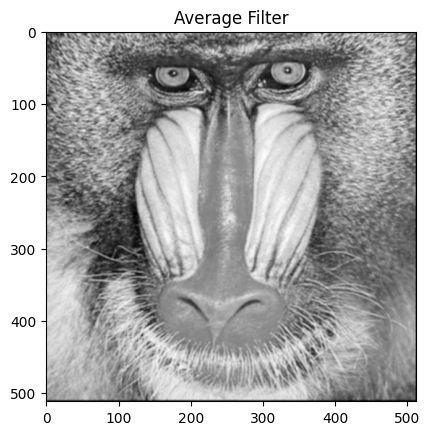

In [141]:
# Average Filter 3x3
kernel_average = np.ones(
    (3,3)
)/9


hasil_average = convolution2d(
    img_gray,
    kernel_average,
    padding=1
)


plt.imshow(
    hasil_average,
    cmap='gray'
)

plt.title(
    "Average Filter"
)

plt.axis("on")
plt.show()

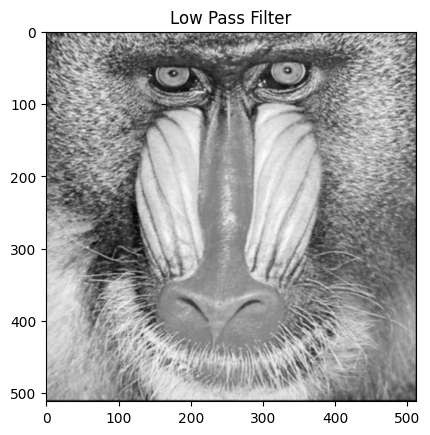

In [142]:
# Low Pass Filter
kernel_lowpass = np.array([
    [1,1,1],
    [1,4,1],
    [1,1,1]
]) / 12


hasil_lowpass = convolution2d(
    img_gray,
    kernel_lowpass,
    padding=1
)


plt.imshow(
    hasil_lowpass,
    cmap='gray'
)

plt.title(
    "Low Pass Filter"
)

plt.axis("on")
plt.show()

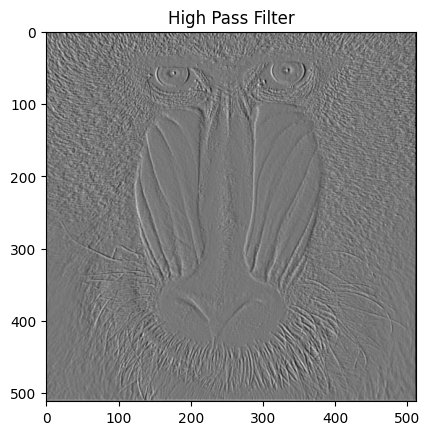

In [143]:
# High Pass Filter
kernel_highpass = np.array([
    [-1,0,1],
    [-1,0,3],
    [-3,0,1]
])


hasil_highpass = convolution2d(
    img_gray,
    kernel_highpass,
    padding=1
)


plt.imshow(
    hasil_highpass,
    cmap='gray'
)

plt.title(
    "High Pass Filter"
)

plt.axis("on")
plt.show()

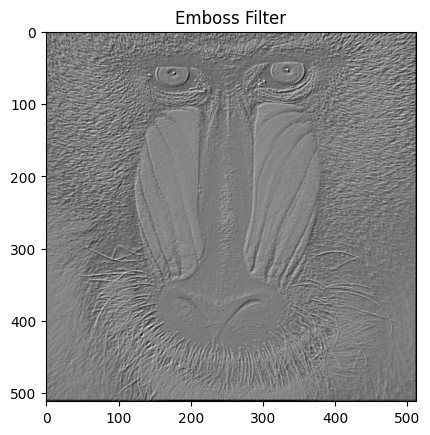

In [144]:
# Emboss Filter
kernel_emboss = np.array([
    [-2,-1,0],
    [-1,1,1],
    [0,1,2]
])


hasil_emboss = convolution2d(
    img_gray,
    kernel_emboss,
    padding=1
)


plt.imshow(
    hasil_emboss,
    cmap='gray'
)

plt.title(
    "Emboss Filter"
)

plt.axis("on")
plt.show()

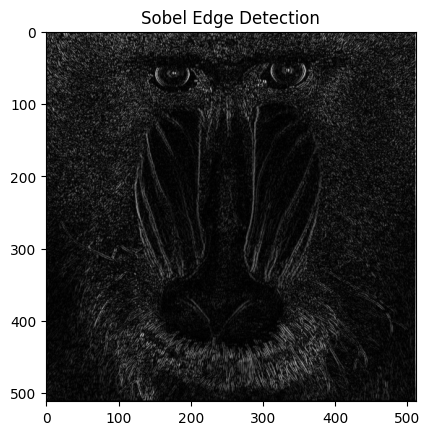

In [145]:
# Kernel Left Sobel
kernel_sobel = np.array([
    [1,0,-1],
    [2,0,-2],
    [1,0,-1]
])


hasil_sobel = convolution2d(
    img_gray,
    kernel_sobel,
    padding=1
)


plt.imshow(
    abs(hasil_sobel),
    cmap='gray'
)

plt.title(
    "Sobel Edge Detection"
)

plt.axis("on")
plt.show()

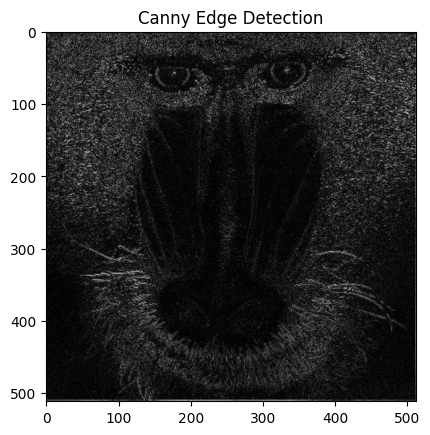

In [146]:
# Canny Edge Detection
kernel_canny = np.array([
    [-1,-1,-1],
    [-1,8,-1],
    [-1,-1,-1]
])


hasil_canny = convolution2d(
    img_gray,
    kernel_canny,
    padding=1
)


plt.imshow(
    abs(hasil_canny),
    cmap='gray'
)

plt.title(
    "Canny Edge Detection"
)

plt.axis("on")
plt.show()

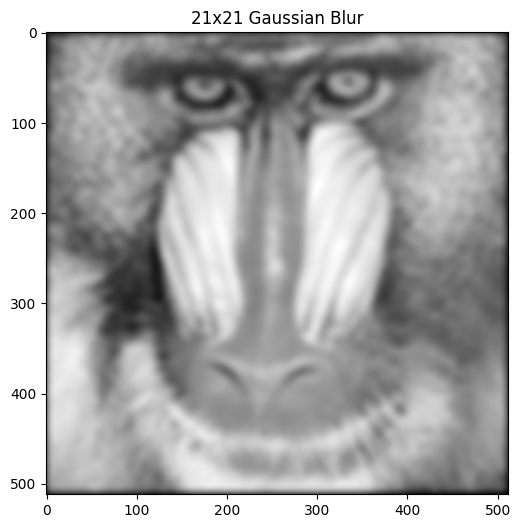

In [147]:
# 21x21 Gaussian Blur
kernel_size = 21

# Generate Gaussian Kernel
sigma = math.sqrt(kernel_size)

gaussian_kernel = cv.getGaussianKernel(
    kernel_size,
    sigma
)

gauss_kernel = gaussian_kernel @ gaussian_kernel.transpose()


# Proses Gaussian Blur menggunakan konvolusi manual
hasil_gaussian = convolution2d(
    img_gray,
    gauss_kernel,
    padding=10
)


# Normalisasi hasil agar dapat ditampilkan
hasil_gaussian = cv.normalize(
    hasil_gaussian,
    None,
    0,
    255,
    cv.NORM_MINMAX
)

hasil_gaussian = hasil_gaussian.astype(np.uint8)



# Menampilkan hasil
plt.figure(figsize=(6,6))

plt.imshow(
    hasil_gaussian,
    cmap="gray"
)

plt.title(
    "21x21 Gaussian Blur"
)

plt.axis("on")

plt.show()



FILTER LIBRARY DAN FILTER MODERN

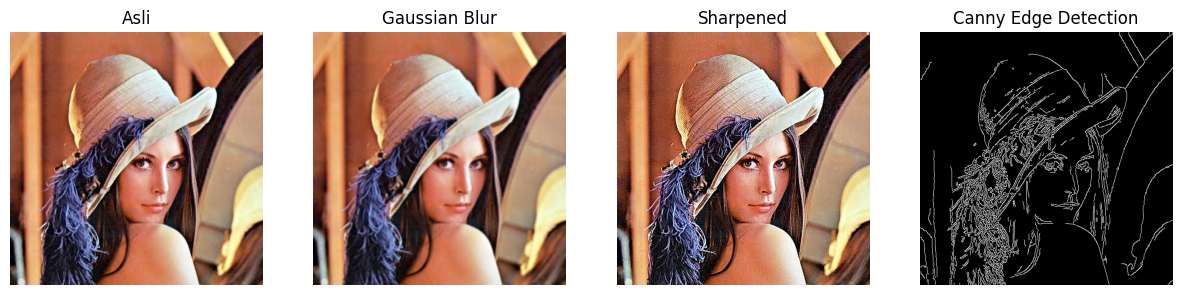

In [148]:
# PERCOBAAN 1
# Fungsi tampil berdampingan

def show_side_by_side(images, titles, figsize=(15,5)):
    plt.figure(figsize=figsize)

    for i, (img, title) in enumerate(zip(images, titles)):

        if len(img.shape) == 2: # grayscale
            plt.subplot(1, len(images), i+1)
            plt.imshow(img, cmap="gray")

        else: # color
            plt.subplot(1, len(images), i+1)
            plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))

        plt.title(title)
        plt.axis("off")

    plt.show()


img = cv.imread(
    "/content/drive/MyDrive/PCVK/Images/lena.jpg"
)

img_gray = cv.cvtColor(
    img,
    cv.COLOR_BGR2GRAY
)


blur = cv.GaussianBlur(
    img,
    (7,7),
    1
)


edges = cv.Canny(
    cv.cvtColor(img, cv.COLOR_BGR2GRAY),
    100,
    200
)


sharpen_kernel = np.array(
    [
        [0,-1,0],
        [-1,5,-1],
        [0,-1,0]
    ]
)


sharpened = cv.filter2D(
    img,
    -1,
    sharpen_kernel
)


show_side_by_side(
    [
        img,
        blur,
        sharpened,
        edges
    ],

    [
        "Asli",
        "Gaussian Blur",
        "Sharpened",
        "Canny Edge Detection"
    ]
)

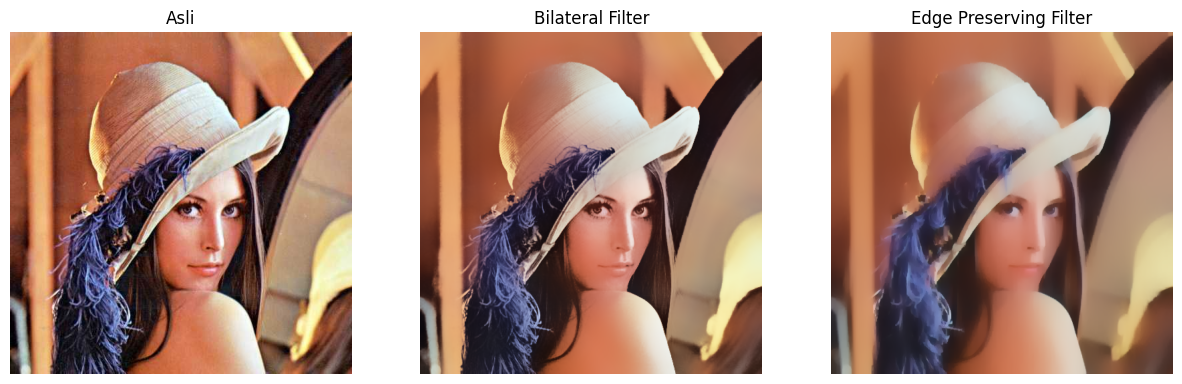

In [149]:
# PERCOBAAN 2
# Filter Modern dari OpenCV
# Bilateral Filter (edge-preserving)

bilateral = cv.bilateralFilter(
    img,
    50,
    100,
    100
)


# Edge Preserving Filter (alternatif Guided Filter)

edge_preserve = cv.edgePreservingFilter(
    img,
    flags=1,
    sigma_s=100,
    sigma_r=0.9
)


show_side_by_side(
    [
        img,
        bilateral,
        edge_preserve
    ],

    [
        "Asli",
        "Bilateral Filter",
        "Edge Preserving Filter"
    ]
)

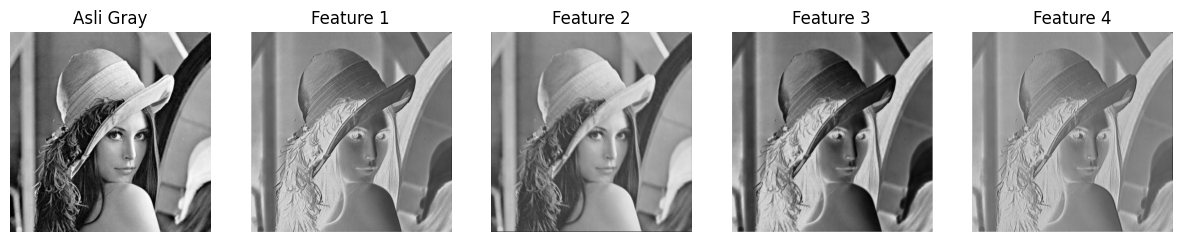

In [150]:
# PERCOBAAN 3
# Filter Feature Map yang digunakan pada CNN, lakukan running code bagian ini beberapa kali dan perhatikan hasilnya

import torch
import torch.nn as nn


class SimpleCNN(nn.Module):

    def __init__(self):

        super(SimpleCNN, self).__init__()

        self.conv1 = nn.Conv2d(
            1,
            4,
            kernel_size=3,
            stride=1,
            padding=1
        )


    def forward(self, x):

        return self.conv1(x)



model = SimpleCNN()


# Ubah gambar ke tensor

img_tensor = torch.tensor(
    img_gray,
    dtype=torch.float32
).unsqueeze(0).unsqueeze(0) / 255.0



# Hasil CNN

with torch.no_grad():

    features = model(
        img_tensor
    )



# Visualisasi feature maps

feature_maps = [
    features[0,i].numpy()
    for i in range(features.shape[1])
]


show_side_by_side(
    [img_gray] + feature_maps,

    [
        "Asli Gray"
    ] + [
        f"Feature {i+1}"
        for i in range(len(feature_maps))
    ]
)

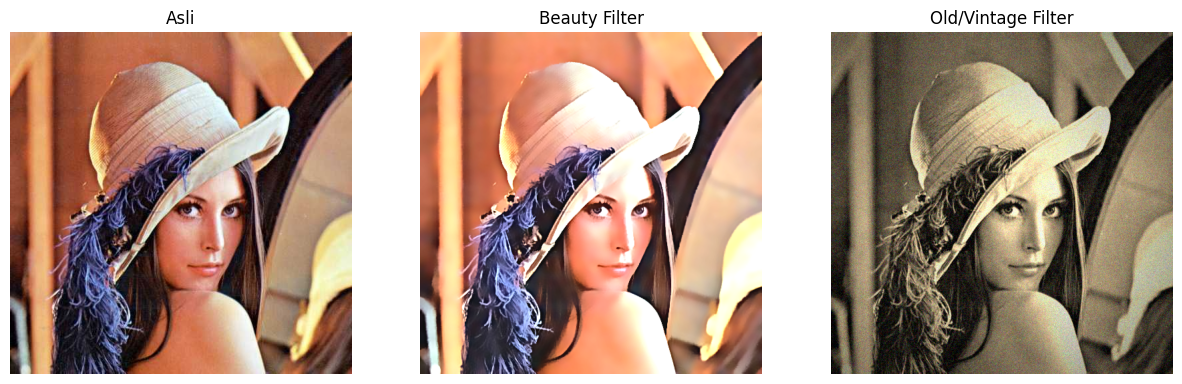

In [151]:
# ===========================
# Percobaan 4
# Beauty Filter & Old/Vintage Filter
# ===========================


# ===========================
# 1. Beauty Filter
# ===========================

# Step 1: Smoothing kulit dengan bilateral filter

smooth = cv.bilateralFilter(
    img,
    d=15,
    sigmaColor=75,
    sigmaSpace=75
)


# Step 2: Unsharp masking (pertajam mata/bibir)

gaussian = cv.GaussianBlur(
    smooth,
    (0,0),
    3
)

sharpened = cv.addWeighted(
    smooth,
    1.5,
    gaussian,
    -0.5,
    0
)


# Step 3: Brightness & contrast

alpha = 1.2   # contrast
beta = 15     # brightness

beauty = cv.convertScaleAbs(
    sharpened,
    alpha=alpha,
    beta=beta
)



# ===========================
# 2. Old/Vintage Filter
# ===========================


# Step 1: Sepia tone

sepia_kernel = np.array(
    [
        [0.272, 0.534, 0.131],
        [0.349, 0.686, 0.168],
        [0.393, 0.769, 0.189]
    ]
)


sepia = cv.transform(
    img,
    sepia_kernel
)


sepia = np.clip(
    sepia,
    0,
    255
).astype(np.uint8)



# Step 2: Vignette

rows, cols = img.shape[:2]


kernel_x = cv.getGaussianKernel(
    cols,
    cols*0.6
)


kernel_y = cv.getGaussianKernel(
    rows,
    rows*0.6
)


kernel = kernel_y * kernel_x.T


mask = kernel / kernel.max()


vignette = np.copy(sepia)


for i in range(3):

    vignette[:,:,i] = (
        vignette[:,:,i] * mask
    )



# Step 3: Noise/Grain

noise = np.random.normal(
    0,
    15,
    vignette.shape
).astype(np.int16)


old_img = np.clip(
    vignette.astype(np.int16) + noise,
    0,
    255
).astype(np.uint8)



# ===========================
# Menampilkan hasil
# ===========================

show_side_by_side(
    [
        img,
        beauty,
        old_img
    ],

    [
        "Asli",
        "Beauty Filter",
        "Old/Vintage Filter"
    ]
)

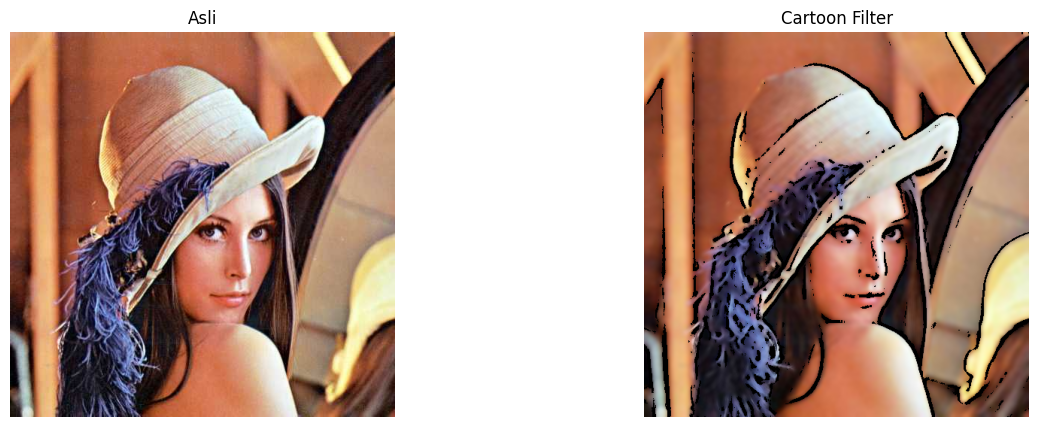

In [152]:
# PERCOBAAN 5
# Filter Anime / Cartoon

# Step 1: Edge detection (pakai median blur dulu agar gambar menjadi lebih halus)

gray = cv.cvtColor(
    img,
    cv.COLOR_BGR2GRAY
)

gray_blur = cv.medianBlur(
    gray,
    7
)


edges = cv.adaptiveThreshold(
    gray_blur,
    255,
    cv.ADAPTIVE_THRESH_MEAN_C,
    cv.THRESH_BINARY,
    9,
    9
)


# Step 2: Bilateral filter untuk smoothing warna

color = cv.bilateralFilter(
    img,
    d=9,
    sigmaColor=200,
    sigmaSpace=200
)


# Step 3: Gabungkan (cartoonize)

cartoon = cv.bitwise_and(
    color,
    color,
    mask=edges
)


# Tampilkan

show_side_by_side(
    [
        img,
        cartoon
    ],

    [
        "Asli",
        "Cartoon Filter"
    ]
)

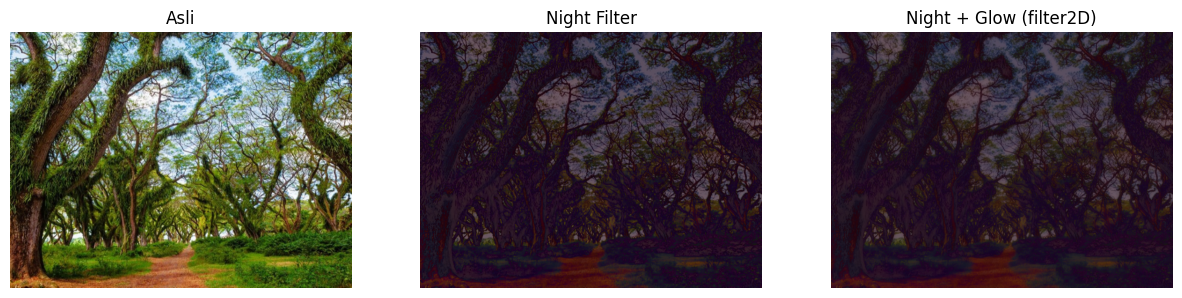

In [153]:
# PERCOBAAN 6
# Night Filter

img = cv.imread(
    "/content/drive/MyDrive/PCVK/Images/Djawatan.jpg"
)


img_gray = cv.cvtColor(
    img,
    cv.COLOR_BGR2GRAY
)


# Step 1: Gelapkan (contrast turun, brightness negatif)

night = cv.convertScaleAbs(
    img,
    alpha=0.6,
    beta=-40
)


# Step 2: Tambah bias biru

blue_tint = np.full_like(
    night,
    (50,0,100)
)


# BGR

night = cv.addWeighted(
    night,
    0.8,
    blue_tint,
    0.2,
    0
)


# Step 3: Efek glow di area terang dengan filter2D

kernel = np.ones(
    (15,15),
    np.float32
) / 225


glow = cv.filter2D(
    night,
    -1,
    kernel
)


# Kombinasikan asli + glow

night_glow = cv.addWeighted(
    night,
    0.7,
    glow,
    0.3,
    0
)


show_side_by_side(
    [
        img,
        night,
        night_glow
    ],

    [
        "Asli",
        "Night Filter",
        "Night + Glow (filter2D)"
    ]
)

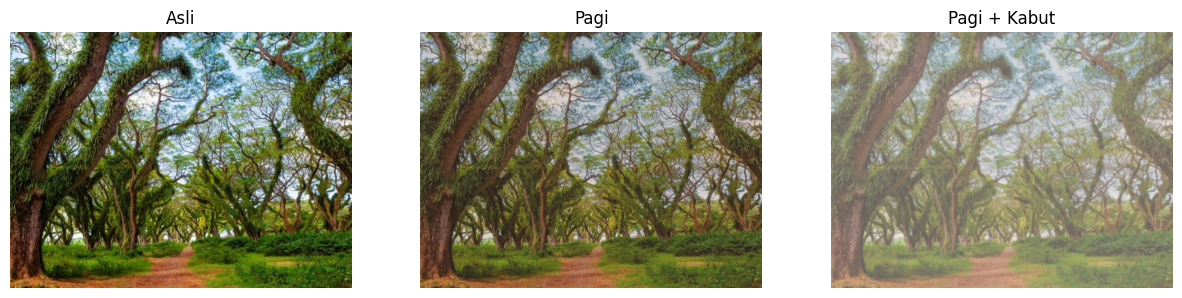

In [154]:
# PERCOBAAN 7
# Filter Suasana pagi dan Kabut


# Step 1: Kurangi kontras & cerahkan

alpha = 0.9
beta = 20


soft = cv.convertScaleAbs(
    img,
    alpha=alpha,
    beta=beta
)



# Step 2: Tambahkan warm tone (kemerahan / orange)

warm_tint = np.full_like(
    soft,
    (40,70,120)
)  # BGR


pagi = cv.addWeighted(
    soft,
    0.8,
    warm_tint,
    0.2,
    0
)



# Step 3: Tambahkan haze (kabut tipis) dengan filter2D


kernel = cv.getGaussianKernel(
    3,
    3
)

kernel = kernel @ kernel.T


kabut = cv.filter2D(
    pagi,
    -1,
    kernel
)


# Tambah layer putih untuk kabut lebih nyata

white_layer = np.full_like(
    pagi,
    255
)


kabut = cv.addWeighted(
    kabut,
    0.7,
    white_layer,
    0.3,
    0
)



show_side_by_side(
    [
        img,
        pagi,
        kabut
    ],

    [
        "Asli",
        "Pagi",
        "Pagi + Kabut"
    ]
)

Tugas Praktikum

1. Tugas Analisis: Perbandingan Mean Filter (Blur Biasa) vs. Median Filter pada Noise “Salt and
Pepper”
  * a. Tambahkan noise bintik hitam-putih (Salt and Pepper) ke sebuah citra keabuan (grayscale).
  * b. Terapkan Mean Filter(3 x 3) dan Median Filter (3 x 3).
  * c. Amati dan analisis secara visual mengapa Median Filter jauh lebih bersih dalam menghapus
noise tersebut dibanding Mean Filter.

In [155]:
# Import Library
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

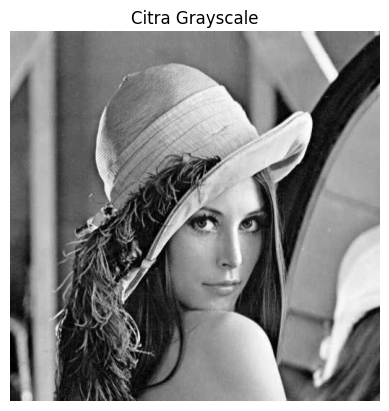

In [156]:
# Load Citra dan Ubah ke Grayscale
img = cv.imread(
    "/content/drive/MyDrive/PCVK/Images/lena.jpg"
)


img_gray = cv.cvtColor(
    img,
    cv.COLOR_BGR2GRAY
)


plt.imshow(
    img_gray,
    cmap="gray"
)

plt.title(
    "Citra Grayscale"
)

plt.axis("off")

plt.show()

In [157]:
# Membuat Noise Salt and Pepper
def salt_pepper_noise(image, amount=0.05):

    noisy = image.copy()

    total_pixels = image.size


    # Pepper noise

    num_pepper = int(
        total_pixels * amount / 2
    )


    coords = [
        np.random.randint(
            0,
            i-1,
            num_pepper
        )
        for i in image.shape
    ]


    noisy[tuple(coords)] = 0



    # Salt noise

    num_salt = int(
        total_pixels * amount / 2
    )


    coords = [
        np.random.randint(
            0,
            i-1,
            num_salt
        )
        for i in image.shape
    ]


    noisy[tuple(coords)] = 255


    return noisy

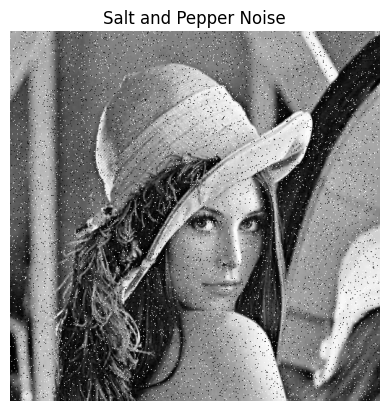

In [158]:
# Tambahkan Noise
img_noise = salt_pepper_noise(
    img_gray,
    amount=0.05
)


plt.imshow(
    img_noise,
    cmap="gray"
)

plt.title(
    "Salt and Pepper Noise"
)

plt.axis("off")

plt.show()

In [159]:
# Mean Filter 3×3
mean_filter = cv.blur(
    img_noise,
    (3,3)
)

In [160]:
# Median Filter 3×3
median_filter = cv.medianBlur(
    img_noise,
    3
)

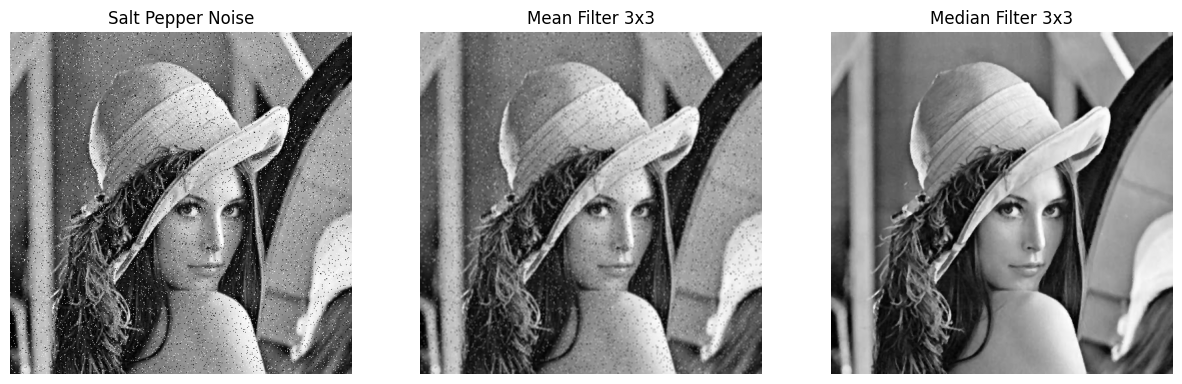

In [161]:
# Tampilkan Perbandingan
show_side_by_side(
    [
        img_noise,
        mean_filter,
        median_filter
    ],

    [
        "Salt Pepper Noise",
        "Mean Filter 3x3",
        "Median Filter 3x3"
    ]
)

####Hasil Analisis
Berdasarkan hasil percobaan, Mean Filter 3×3 mampu mengurangi noise Salt and Pepper, tetapi menyebabkan citra menjadi lebih blur karena proses perataan menggunakan nilai rata-rata piksel tetangga sehingga detail tepi ikut berkurang.

Sedangkan Median Filter 3×3 mampu menghilangkan noise Salt and Pepper dengan lebih baik. Hal ini karena Median Filter menggunakan nilai tengah dari piksel tetangga sehingga nilai ekstrem (hitam 0 dan putih 255) akibat noise tidak terlalu mempengaruhi hasil.

Dapat disimpulkan bahwa Median Filter lebih efektif dibandingkan Mean Filter dalam mengatasi noise Salt and Pepper karena mampu membersihkan noise dengan tetap mempertahankan detail citra.

2. Tugas Evaluasi: Pemilihan Ukuran Kernel terbaik untuk Menajamkan Citra (Sharpening)
* a. Buat kernel penajaman (Sharpening Kernel) ukuran 3 x 3 dan 5 x 5.
* b. Terapkan pada citra yang sedikit buram (blurry).
* c. Evaluasi hasilnya berdasarkan aspek Kejelasan Tepi vs. Kadar Noise/Noise Distortion yang
dihasilkan. Tentukan kernel mana yang paling optimal untuk digunakan sehari-hari.

In [162]:
# Load Citra dan Buat Citra Blur

img = cv.imread(
    "/content/drive/MyDrive/PCVK/Images/lena.jpg"
)


# Buat citra grayscale

img_gray = cv.cvtColor(
    img,
    cv.COLOR_BGR2GRAY
)


# Buat efek blur

blur = cv.GaussianBlur(
    img_gray,
    (7,7),
    0
)

In [163]:
# Sharpening Kernel 3×3
kernel_3x3 = np.array([
    [0,-1,0],
    [-1,5,-1],
    [0,-1,0]
])


sharpen_3x3 = cv.filter2D(
    blur,
    -1,
    kernel_3x3
)

In [164]:
# Sharpening Kernel 5×5
kernel_5x5 = np.array([
    [-1,-1,-1,-1,-1],
    [-1,1,1,1,-1],
    [-1,1,9,1,-1],
    [-1,1,1,1,-1],
    [-1,-1,-1,-1,-1]
]) / 9


sharpen_5x5 = cv.filter2D(
    blur,
    -1,
    kernel_5x5
)

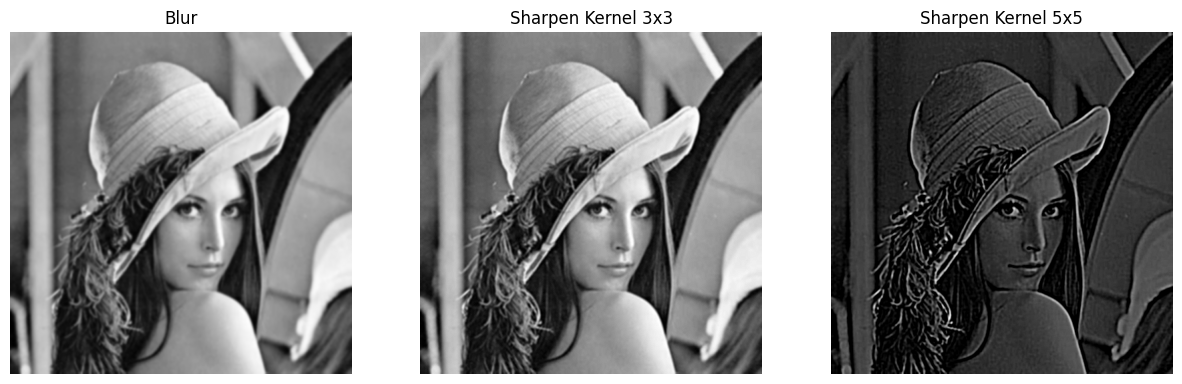

In [165]:
# Menampilkan Hasil Perbandingan
show_side_by_side(
    [
        blur,
        sharpen_3x3,
        sharpen_5x5
    ],

    [
        "Blur",
        "Sharpen Kernel 3x3",
        "Sharpen Kernel 5x5"
    ]
)

####Hasil Analisis
Berdasarkan hasil percobaan, kernel sharpening 3×3 mampu meningkatkan ketajaman tepi citra dengan baik serta tetap mempertahankan detail citra dengan noise yang relatif rendah. Sementara itu, kernel 5×5 menghasilkan efek penajaman yang lebih kuat, terlihat dari tepi objek yang lebih menonjol, namun menyebabkan peningkatan kontras dan distorsi pada beberapa bagian citra.

Dapat disimpulkan bahwa kernel 3×3 lebih optimal untuk penggunaan sehari-hari karena memberikan keseimbangan antara peningkatan detail tepi dan tingkat noise yang lebih rendah dibandingkan kernel 5×5.

3. Tugas Kreasi: Filter Kartun Sederhana
    1. Buatlah sebuah fungsi kustom bernama kartun(image) yang menggabungkan:
        * Penghalusan warna menggunakan **Bilateral Filter** agar area warna menjadi rata.
        * Deteksi garis tepi menggunakan **Adaptive Thresholding** atau **Canny Edge**.
        * Penggabungan (kombinasi) keduanya menggunakan operasi logika/perkalian piksel.
    2. Tampilkan hasil citra asli dengan citra efek kartun bersebelahan.

In [166]:
# Membuat Fungsi kartun(image)
def kartun(image):

    # Step 1: Deteksi tepi
    gray = cv.cvtColor(
        image,
        cv.COLOR_BGR2GRAY
    )


    gray_blur = cv.medianBlur(
        gray,
        7
    )


    edges = cv.adaptiveThreshold(
        gray_blur,
        255,
        cv.ADAPTIVE_THRESH_MEAN_C,
        cv.THRESH_BINARY,
        9,
        9
    )


    # Step 2: Smoothing warna menggunakan Bilateral Filter

    color = cv.bilateralFilter(
        image,
        d=9,
        sigmaColor=200,
        sigmaSpace=200
    )


    # Step 3: Gabungkan warna dan garis

    cartoon = cv.bitwise_and(
        color,
        color,
        mask=edges
    )


    return cartoon

In [167]:
# Membaca Citra
img = cv.imread(
    "/content/drive/MyDrive/PCVK/Images/lena.jpg"
)

In [168]:
# Jalankan Fungsi Cartoon
hasil_kartun = kartun(
    img
)

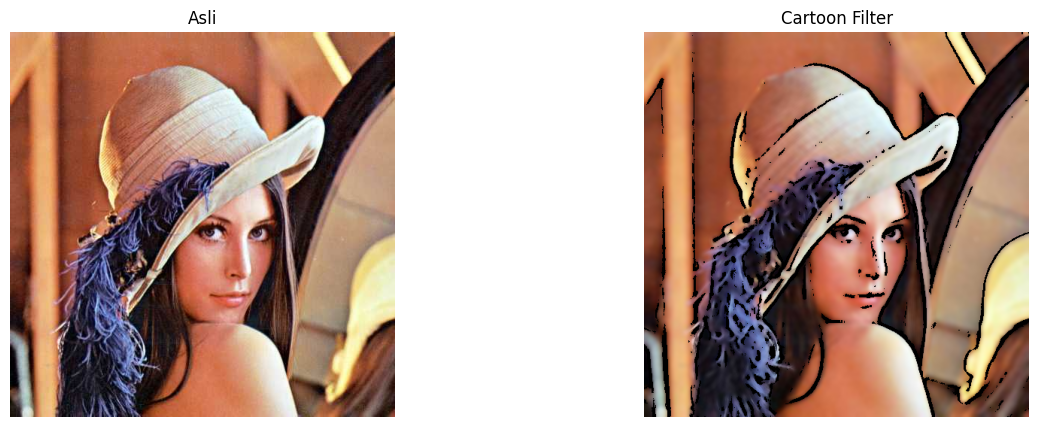

In [169]:
# Menampilkan Hasil
show_side_by_side(
    [
        img,
        hasil_kartun
    ],

    [
        "Asli",
        "Cartoon Filter"
    ]
)

#### Hasil Analisis
Berdasarkan hasil percobaan, filter kartun berhasil mengubah citra asli menjadi tampilan seperti ilustrasi dengan mempertahankan garis tepi objek dan menghaluskan variasi warna. Bilateral Filter membantu menjaga detail tepi saat melakukan penghalusan warna, sedangkan Adaptive Threshold digunakan untuk menghasilkan garis yang memperkuat bentuk objek.

Dapat disimpulkan bahwa kombinasi smoothing warna dan deteksi tepi dapat menghasilkan efek kartun sederhana dengan mempertahankan struktur utama dari citra asli.